In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)


In [38]:
df = pd.read_csv('CarPrice_Assignment.csv')
df.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


Пропуски по колонкам:
Пропусков нет!


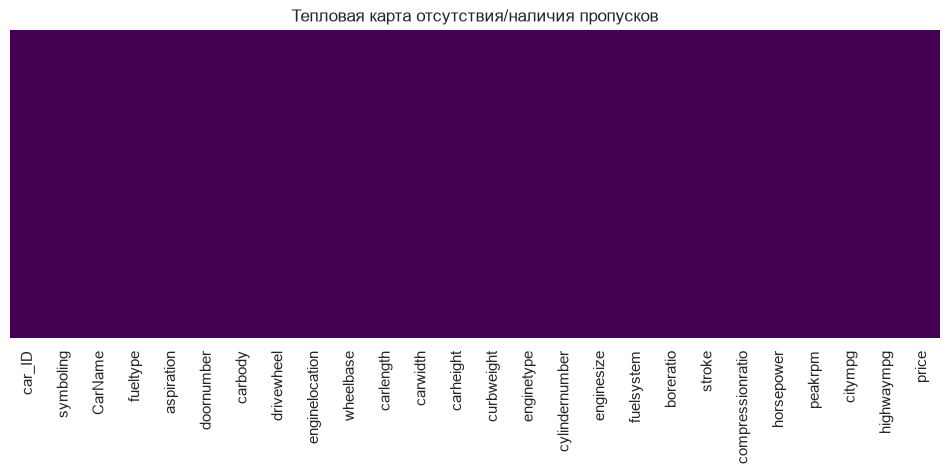

In [39]:
# 1. Проверка пропусков текстом
missing_values = df.isnull().sum()
print("Пропуски по колонкам:")
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "Пропусков нет!")

# 2. Графическая проверка (тепловая карта)
plt.figure(figsize=(12, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title("Тепловая карта отсутствия/наличия пропусков")
plt.show()

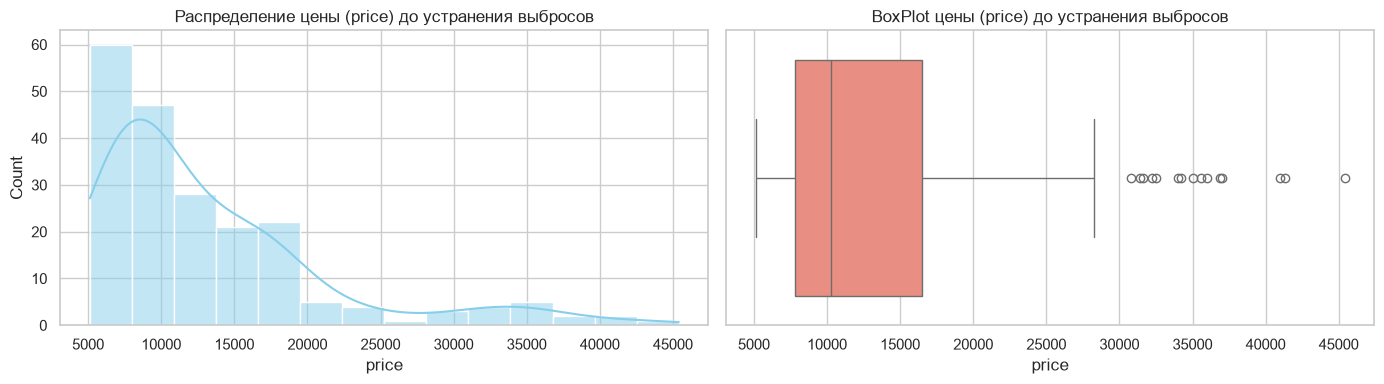

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# График распределения
sns.histplot(df['price'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Распределение цены (price) до устранения выбросов')

# BoxPlot
sns.boxplot(x=df['price'], ax=axes[1], color='salmon')
axes[1].set_title('BoxPlot цены (price) до устранения выбросов')

plt.tight_layout()
plt.show()

Нижняя граница: -5284.50, Верхняя граница: 29575.50


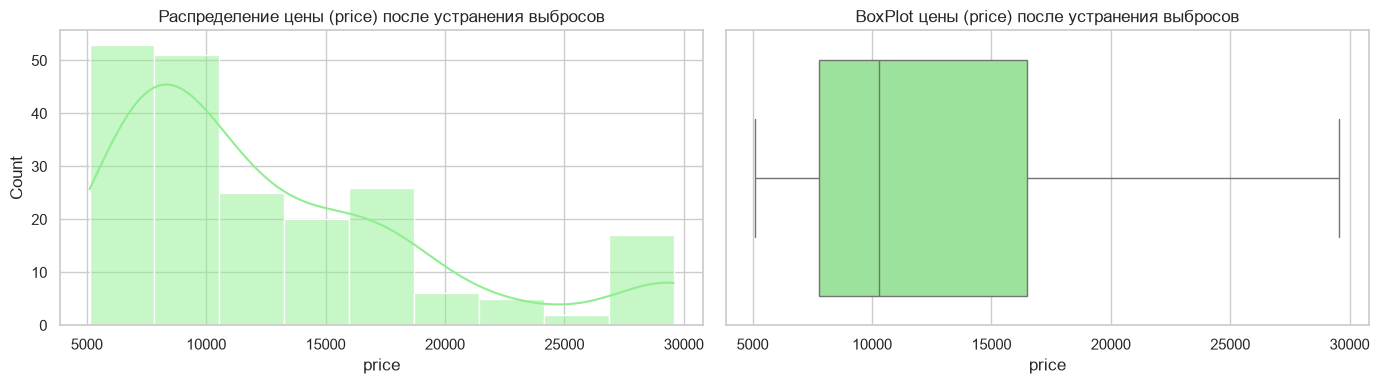

In [41]:
# Расчет границ по межквартильному размаху (IQR)
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Нижняя граница: {lower_bound:.2f}, Верхняя граница: {upper_bound:.2f}")

# Ограничиваем выбросы (клиппинг/винзоризация)
df['price'] = df['price'].clip(lower=lower_bound, upper=upper_bound)

# Проверка графическими средствами после
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df['price'], kde=True, ax=axes[0], color='lightgreen')
axes[0].set_title('Распределение цены (price) после устранения выбросов')

sns.boxplot(x=df['price'], ax=axes[1], color='lightgreen')
axes[1].set_title('BoxPlot цены (price) после устранения выбросов')

plt.tight_layout()
plt.show()

In [42]:
# 1. Извлечение марки автомобиля из полного названия 'CarName' 
df['brand'] = df['CarName'].apply(lambda x: str(x).split(' ')[0].lower())

# 2. Соотношение массы автомобиля к мощности (удельная масса curbweight / horsepower)
df['weight_to_power'] = df['curbweight'] / df['horsepower']

# 3. Бинарный признак: мощный ли автомобиль (1 если выше медианы, 0 если ниже)
df['is_high_power'] = (df['horsepower'] > df['horsepower'].median()).astype(int)

# Удаление вспомогательных/уникальных колонок car_ID и исходный CarName
df_processed = df.drop(columns=['car_ID', 'CarName'])

print("Новые признаки успешно добавлены!")
df_processed[['brand', 'weight_to_power', 'is_high_power']].head()

Новые признаки успешно добавлены!


,brand,weight_to_power,is_high_power
0,alfa-romero,22.954955,1
1,alfa-romero,22.954955,1
2,alfa-romero,18.331169,1
3,audi,22.911765,1
4,audi,24.556522,1


In [43]:
# Текстовые колонки
cat_cols = df_processed.select_dtypes(include=['object', 'str']).columns.tolist()
print("Категориальные столбцы для кодирования:", cat_cols)

# One-Hot Encoding (OHE) с drop_first=True
df_encoded = pd.get_dummies(df_processed, columns=cat_cols, drop_first=True)

print("Размер датасета после OHE:", df_encoded.shape)
df_encoded.head()

Категориальные столбцы для кодирования: ['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem', 'brand']
Размер датасета после OHE: (205, 72)


,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,...,brand_porsche,brand_renault,brand_saab,brand_subaru,brand_toyota,brand_toyouta,brand_vokswagen,brand_volkswagen,brand_volvo,brand_vw
0,3,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,...,False,False,False,False,False,False,False,False,False,False
1,3,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,...,False,False,False,False,False,False,False,False,False,False
2,1,94.5,171.2,65.5,52.4,2823,152,2.68,3.47,9.0,...,False,False,False,False,False,False,False,False,False,False
3,2,99.8,176.6,66.2,54.3,2337,109,3.19,3.40,10.0,...,False,False,False,False,False,False,False,False,False,False
4,2,99.4,176.6,66.4,54.3,2824,136,3.19,3.40,8.0,...,False,False,False,False,False,False,False,False,False,False


In [44]:
# Числовые непрерывные признаки (исключая бинарные флаги 0/1)
num_cols = ['wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 
            'enginesize', 'boreratio', 'stroke', 'compressionratio', 
            'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price', 'weight_to_power']

# 1. Стандартизация (Z-score: mean = 0, std = 1)
scaler_std = StandardScaler()
df_standardized = df_encoded.copy()
df_standardized[num_cols] = scaler_std.fit_transform(df_encoded[num_cols])

# 2. Нормализация (MinMax: диапазон от 0 до 1)
scaler_minmax = MinMaxScaler()
df_normalized = df_encoded.copy()
df_normalized[num_cols] = scaler_minmax.fit_transform(df_encoded[num_cols])

print("Стандартизированные данные (describe):")
display(df_standardized[num_cols].describe().round(2).iloc[:3])

print("Нормализованные данные (describe - мин. и макс. теперь 0 и 1):")
display(df_normalized[num_cols].describe().round(2).loc[['min', 'max']])

Стандартизированные данные (describe):


,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,weight_to_power
count,205.0,205.0,205.0,205.0,205.0,205.0,205.0,205.0,205.0,205.0,205.0,205.0,205.0,205.0,205.0
mean,-0.0,0.0,0.0,-0.0,0.0,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


Нормализованные данные (describe - мин. и макс. теперь 0 и 1):


,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,weight_to_power
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
